In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import(train_test_split,StratifiedKFold,GridSearchCV)
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (accuracy_score,recall_score,precision_score,f1_score,confusion_matrix,classification_report)

import warnings
warnings.filterwarnings('ignore')
RANDOM_STATE = 42

In [3]:
df = pd.read_csv("heart.csv")
print("Dataset Shape:",df.shape)
df.head()

Dataset Shape: (1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [4]:
df.info()
df.describe().T


<class 'pandas.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.434146,9.072290,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.695610,0.460373,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.942439,1.029641,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.611707,17.516718,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.000000,51.592510,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.149268,0.356527,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.529756,0.527878,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.114146,23.005724,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.336585,0.472772,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.071512,1.175053,0.0,0.0,0.8,1.8,6.2


In [5]:
print("Missing values:",df.isnull().sum())

Missing values: age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


In [6]:
print("Duplicate rows:",df.duplicated().sum())

Duplicate rows: 723


In [7]:
print(df['target'].value_counts())
print(df['target'].value_counts(normalize=True)*100)

target
1    526
0    499
Name: count, dtype: int64
target
1    51.317073
0    48.682927
Name: proportion, dtype: float64


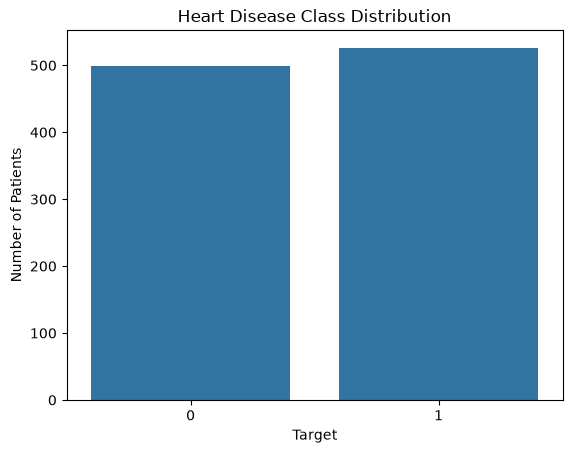

In [8]:
sns.countplot(data=df,x='target')
plt.title("Heart Disease Class Distribution")
plt.xlabel("Target")
plt.ylabel("Number of Patients")
plt.show()

In [9]:
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:",df.shape)

Shape after removing duplicates: (302, 14)


In [10]:
x = df.drop('target',axis=1)
y = df['target']
print("X shape:",x.shape)
print("y shape:",y.shape)

X shape: (302, 13)
y shape: (302,)


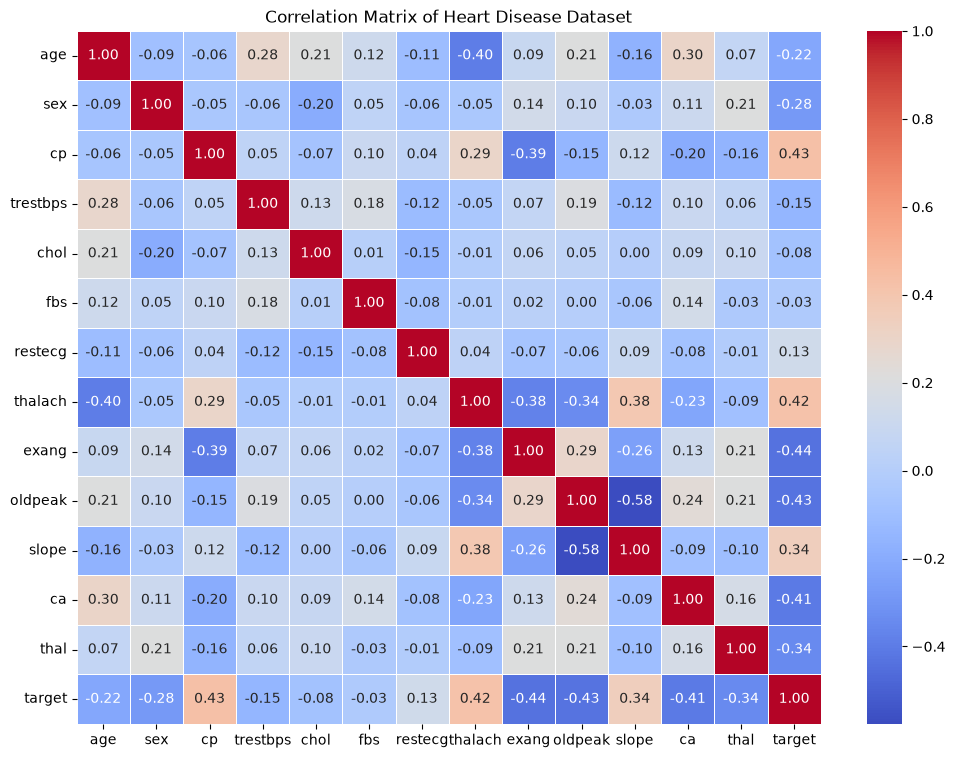

In [11]:
corr_matrix = df.corr(numeric_only=True)
plt.figure(figsize=(12,9))
sns.heatmap(corr_matrix,annot=True,cmap='coolwarm',fmt='.2f',linewidths=0.5)
plt.title("Correlation Matrix of Heart Disease Dataset")
plt.show()

In [12]:
target_corr = (corr_matrix['target'].drop('target').sort_values(ascending=False))
print(target_corr)

cp          0.432080
thalach     0.419955
slope       0.343940
restecg     0.134874
fbs        -0.026826
chol       -0.081437
trestbps   -0.146269
age        -0.221476
sex        -0.283609
thal       -0.343101
ca         -0.408992
oldpeak    -0.429146
exang      -0.435601
Name: target, dtype: float64


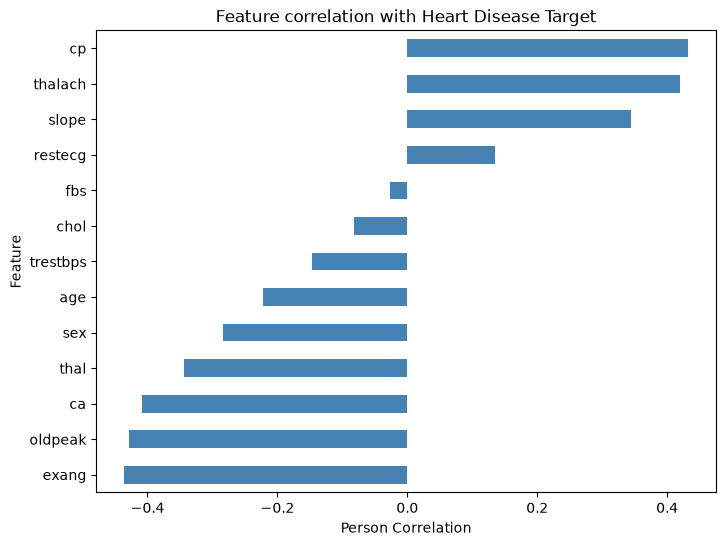

In [14]:
plt.figure(figsize=(8,6))
target_corr.sort_values().plot(kind='barh',color='steelblue')
plt.title("Feature correlation with Heart Disease Target")
plt.xlabel("Person Correlation")
plt.ylabel('Feature')
plt.show()

In [15]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.20,random_state=RANDOM_STATE,stratify=y)
print("Training samples:",x_train.shape[0])
print("Testing samples:",x_test.shape[0])

Training samples: 241
Testing samples: 61


In [17]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
pca_full = PCA()
x_train_pca = pca_full.fit_transform(x_train_scaled)
explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

print("Explained Variance:",explained_variance)
print("Cumulative explained variance:",cumulative_variance)

Explained Variance: [0.20860316 0.12590689 0.10183326 0.08230721 0.0804309  0.07014768
 0.06684163 0.06219018 0.05406655 0.04715893 0.03842388 0.03203648
 0.03005325]
Cumulative explained variance: [0.20860316 0.33451005 0.43634331 0.51865053 0.59908142 0.6692291
 0.73607072 0.79826091 0.85232746 0.89948638 0.93791026 0.96994675
 1.        ]


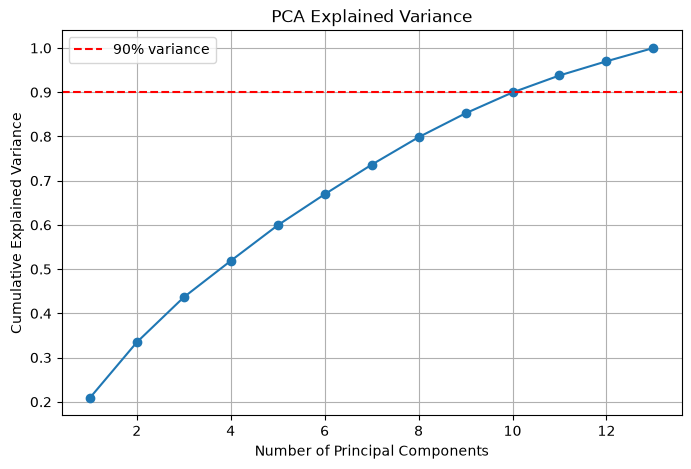

In [19]:
plt.figure(figsize=(8,5))
plt.plot(range(1,len(cumulative_variance)+1),cumulative_variance,marker='o')
plt.axhline(y=0.90,color='red',linestyle='--',label='90% variance')
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")
plt.legend()
plt.grid()
plt.show()

In [20]:
svm_pipeline = Pipeline([('scaler',StandardScaler()),('pca',PCA()),('svm',SVC())])

In [22]:
svm_param_grid={'pca__n_components':[0.80,0.90,0.95,None],'svm__C':[0.1,1,10,100],'svm__kernel':["linear","rbf"],'svm__gamma':["scale","auto"]}

In [23]:
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)

In [24]:
svm_grid = GridSearchCV(estimator=svm_pipeline,param_grid=svm_param_grid,scoring='recall',cv=cv,verbose=1,refit=True)
svm_grid.fit(x_train,y_train)

Fitting 5 folds for each of 64 candidates, totalling 320 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...svm', SVC())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'pca__n_components': [0.8, 0.9, ...], 'svm__C': [0.1, 1, ...], 'svm__gamma': ['scale', 'auto'], 'svm__kernel': ['linear', 'rbf']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple met

In [25]:
print("Best SVM parameters:")
print(svm_grid.best_params_)
print('Best CV recall:')
print(svm_grid.best_score_)

Best SVM parameters:
{'pca__n_components': 0.8, 'svm__C': 0.1, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Best CV recall:
0.9461538461538461


In [26]:
best_svm = svm_grid.best_estimator_

In [27]:
y_pred_svm = best_svm.predict(x_test)

In [28]:
svm_accuracy = accuracy_score(y_test,y_pred_svm)
svm_recall = recall_score(y_test,y_pred_svm)
svm_precision = precision_score(y_test,y_pred_svm)
svm_f1 = f1_score(y_test,y_pred_svm)
print("SVM Results")
print("-"*40)
print(f"Accuracy: {svm_accuracy:.4f}")
print(f"Recall: {svm_recall:.4f}")
print(f"Precision: {svm_precision:.4f}")
print(f"F1 Score: {svm_f1:.4f}")

SVM Results
----------------------------------------
Accuracy: 0.8033
Recall: 0.8788
Precision: 0.7838
F1 Score: 0.8286


In [29]:
print(classification_report(y_test,y_pred_svm))

              precision    recall  f1-score   support

           0       0.83      0.71      0.77        28
           1       0.78      0.88      0.83        33

    accuracy                           0.80        61
   macro avg       0.81      0.80      0.80        61
weighted avg       0.81      0.80      0.80        61



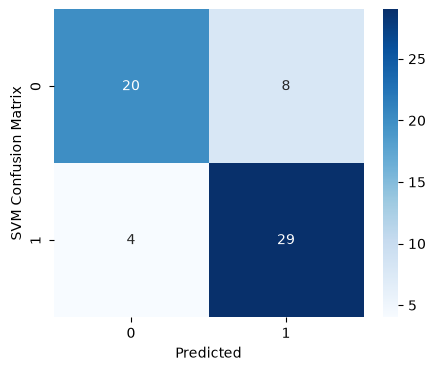

In [30]:
cm_svm = confusion_matrix(y_test,y_pred_svm)
plt.figure(figsize=(5,4))
sns.heatmap(cm_svm,annot=True,fmt='d',cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("SVM Confusion Matrix")
plt.show()

In [34]:
knn_pipeline = Pipeline([('scaler',StandardScaler()),('pca',PCA()),('knn',KNeighborsClassifier())])

In [35]:
knn_param_grid = {'pca__n_components':[0.80,0.90,0.95,None],'knn__n_neighbors':[3,5,7,9,11,15,21],'knn__weights':['uniform','distance'],'knn__p':[1,2]}

In [36]:
knn_grid = GridSearchCV(estimator=knn_pipeline,param_grid=knn_param_grid,scoring='recall',cv=cv,n_jobs=-1,verbose=1,refit=True)
knn_grid.fit(x_train,y_train)

Fitting 5 folds for each of 112 candidates, totalling 560 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'knn__n_neighbors': [3, 5, ...], 'knn__p': [1, 2], 'knn__weights': ['uniform', 'distance'], 'pca__n_components': [0.8, 0.9, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metrice

In [37]:
print("Best KNN parameters:")
print(knn_grid.best_params_)
print('Best CV recall:')
print(knn_grid.best_score_)

Best KNN parameters:
{'knn__n_neighbors': 21, 'knn__p': 2, 'knn__weights': 'uniform', 'pca__n_components': 0.8}
Best CV recall:
0.9384615384615385


In [38]:
best_knn = knn_grid.best_estimator_

In [39]:
y_pred_knn = best_knn.predict(x_test)

In [40]:
knn_accuracy = accuracy_score(y_test,y_pred_knn)
knn_recall = recall_score(y_test,y_pred_knn)
knn_precision = precision_score(y_test,y_pred_knn)
knn_f1 = f1_score(y_test,y_pred_knn)
print("KNN Results")
print('-'*40)
print(f"Accuracy: {knn_accuracy:.4f}")
print(f"Recall: {knn_recall:.4f}")
print(f"Precision: {knn_precision:.4f}")
print(f'F1 Score: {knn_f1:.4f}')

KNN Results
----------------------------------------
Accuracy: 0.8525
Recall: 0.9091
Precision: 0.8333
F1 Score: 0.8696


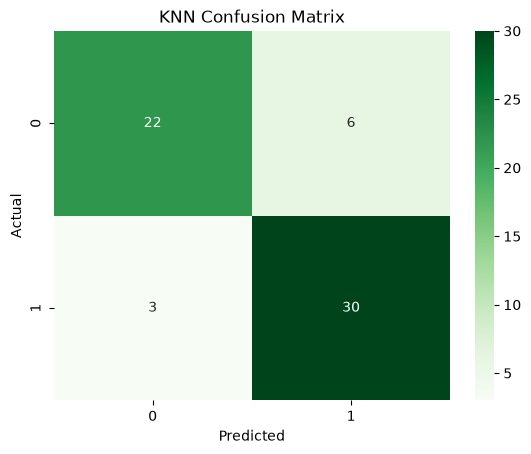

In [41]:
cm_knn = confusion_matrix(y_test,y_pred_knn)
plt.Figure(figsize=(5,4))
sns.heatmap(cm_knn,annot=True,fmt='d',cmap='Greens')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN Confusion Matrix")
plt.show()

In [42]:
results = pd.DataFrame({"Model":["SVM","KNN"],"Accuracy":[svm_accuracy,knn_accuracy],"Recall":[svm_recall,knn_recall],"Precision":[svm_precision,knn_precision],"F1 Score":[svm_f1,knn_f1]})
results

,Model,Accuracy,Recall,Precision,F1 Score
0,SVM,0.803279,0.878788,0.783784,0.828571
1,KNN,0.852459,0.909091,0.833333,0.869565


In [43]:
results.round(4)

,Model,Accuracy,Recall,Precision,F1 Score
0,SVM,0.8033,0.8788,0.7838,0.8286
1,KNN,0.8525,0.9091,0.8333,0.8696


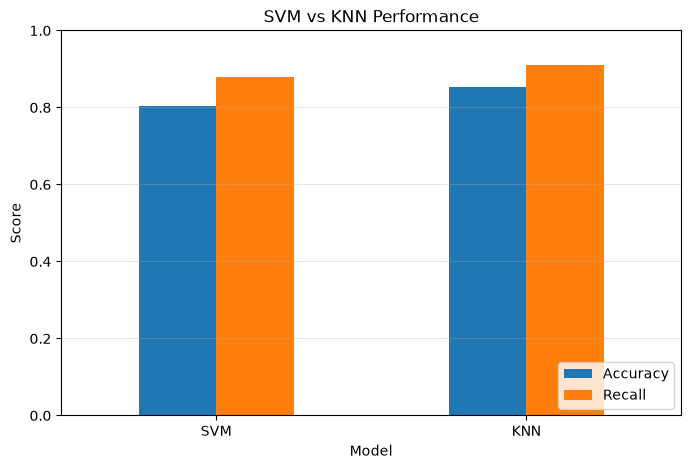

In [45]:
results_plot = results.set_index("Model")[["Accuracy","Recall"]]
results_plot.plot(kind='bar',figsize=(8,5),ylim=(0,1),rot=0)
plt.title("SVM vs KNN Performance")
plt.ylabel("Score")
plt.xlabel("Model")
plt.grid(axis='y',alpha=0.3)
plt.legend(loc='lower right')
plt.show()

In [47]:
scoring = {"accuracy":'accuracy',"recall":'recall',"precision":'precision',"f1":'f1'}
svm_grid_multi = GridSearchCV(svm_pipeline,svm_param_grid,scoring=scoring,refit='recall',cv=cv,n_jobs=-1)
svm_grid_multi.fit(x_train,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...svm', SVC())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'pca__n_components': [0.8, 0.9, ...], 'svm__C': [0.1, 1, ...], 'svm__gamma': ['scale', 'auto'], 'svm__kernel': ['linear', 'rbf']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'accuracy': 'accuracy', 'f1': 'f1', 'precision': 'precision', 'recall': 'recall'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'recall'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... 

In [48]:
knn_grid_multi = GridSearchCV(knn_pipeline,knn_param_grid,scoring=scoring,refit='recall',cv=cv,n_jobs=-1)
knn_grid_multi.fit(x_train,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'knn__n_neighbors': [3, 5, ...], 'knn__p': [1, 2], 'knn__weights': ['uniform', 'distance'], 'pca__n_components': [0.8, 0.9, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'accuracy': 'accuracy', 'f1': 'f1', 'precision': 'precision', 'recall': 'recall'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'recall'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... ve

In [49]:
svm_cv_results = pd.DataFrame(svm_grid_multi.cv_results_)
svm_cv_results[['params','mean_test_accuracy','mean_test_recall','mean_test_precision','mean_test_f1']].sort_values('mean_test_recall',ascending=False).head(10)

,params,mean_test_accuracy,mean_test_recall,mean_test_precision,mean_test_f1
1,"{'pca__n_components': 0.8, 'svm__C': 0.1, 'svm...",0.833673,0.946154,0.799801,0.863419
3,"{'pca__n_components': 0.8, 'svm__C': 0.1, 'svm...",0.833673,0.946154,0.799801,0.863419
19,"{'pca__n_components': 0.9, 'svm__C': 0.1, 'svm...",0.825340,0.946154,0.791595,0.857770
17,"{'pca__n_components': 0.9, 'svm__C': 0.1, 'svm...",0.833673,0.946154,0.800979,0.863479
35,"{'pca__n_components': 0.95, 'svm__C': 0.1, 'sv...",0.825340,0.946154,0.789371,0.857257
33,"{'pca__n_components': 0.95, 'svm__C': 0.1, 'sv...",0.833673,0.946154,0.799801,0.863419
49,"{'pca__n_components': None, 'svm__C': 0.1, 'sv...",0.825340,0.938462,0.792705,0.856026
51,"{'pca__n_components': None, 'svm__C': 0.1, 'sv...",0.825340,0.938462,0.792705,0.856026
60,"{'pca__n_components': None, 'svm__C': 100, 'sv...",0.846173,0.931054,0.823700,0.870776
62,"{'pca__n_components': None, 'svm__C': 100, 'sv...",0.846173,0.931054,0.823700,0.870776


In [50]:
final_results = pd.DataFrame({
    "Model":['SVM','KNN'],"Best CV Recall":[svm_grid_multi.best_score_, knn_grid_multi.best_score_],
    "Test Accuracy":[accuracy_score(y_test,svm_grid_multi.best_estimator_.predict(x_test)),accuracy_score(y_test,knn_grid_multi.best_estimator_.predict(x_test))],
    "Test Recall":[recall_score(y_test,svm_grid_multi.best_estimator_.predict(x_test)),recall_score(y_test,knn_grid_multi.best_estimator_.predict(x_test))]
})
final_results.round(4)

,Model,Best CV Recall,Test Accuracy,Test Recall
0,SVM,0.9462,0.8033,0.8788
1,KNN,0.9385,0.8525,0.9091
